# Data Visualization — Parkir ITN Malang



## 1. Import & Setup

In [ ]:
import io
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

os.makedirs('grafik', exist_ok=True)

## 2. Load Dataset (data kotor)

In [ ]:
DATA_KOTOR = """ID,Plat_Nomor,Jenis,Merk,Model,Warna,Status,Tanggal,Jam_Masuk,Jam_Keluar,Area
1,N 4521 AB,Motor,Honda,Beat,Merah,Mahasiswa,2026-09-01,07:15,15:30,Kampus 1 - Motor
2,n4521ab,motor,HONDA,beat,merah,mahasiswa,01/09/2026,07:20,15:35,kampus 1 - motor
3,N 1287 CD,Mobil,Toyota,Innova,Silver,Dosen,2026-09-01,08:00,16:00,Kampus 1 - Mobil
4,N 6610 XY,Motor,Yamaha,NMAX,Biru,Mahasiswa,1 Sep 2026,7.45,14.10,Kampus 1 - Motor
5,N 9012 EF,mobil,Honda,Brio,Putih,Dosen,2026-09-02,08:30,08:10,Kampus 1 - Mobil
6,AG 7788 GH,Motor,Suzuki,Satria F150,Biru,Mahasiswa,2026-09-02,09:00,17:00,Kampus 2 - Motor
7,N 3456 IJ,Motor,Honda,Vario 125,Biru,Mahasiswa,2026-09-02,07:50,NULL,Kampus 2 - Motor
8,N-2468-KL,Mobil,Daihatsu,Xenia,Hitam,Staf,2026-09-03,07:30,16:30,kampus 1 - mobil
9,DK 1357 MN,Sepeda Motor,Honda,Supra X 125,Hijau,Tamu,2026-09-03,10:00,11:30,Kampus 2 - Motor
10,N 8642 OP,Motor,Honda,PCX,Oranye,Mahasiswa,2026-09-03,25:10,15:00,Kampus 2 - Motor
11,,Motor,Kawasaki,Ninja 250,Hijau,Mahasiswa,2026-09-04,08:05,12:00,Kampus 1 - Motor
12,N 1111 QR,Mobill,Toyota,Avanza,Abu-abu,Dosn,2026-09-04,08:15,17:45,Kampus 1 - Mobil
13,N 2222 ST,Motor,Honda,Scoopy,Kuning,Mahasiswa ,2026-09-04,07:10,16:20,Kampus 3 - Motor
14,N 3333 UV,Motor,yamaha,Mio,Merah,Mahasiswa,04-09-2026,09:30,13:00,Kampus 1 - Motor
15,B 4444 WX,Mobil,Mitsubishi,Xpander,Coklat,Tamu,2026-09-05,13:00,14:00,Kampus 2 - Mobil
16,N 5555 YZ,Motor,Honda,Vario,Coklat,Mahasiswa,2026-09-05,07:00,07:00,Kampus 1 - Motor
17,N 6666 AA,Motor,Honda,Genio,Maroon,Mahasiswa,2026-09-05,06:45,99:99,Kampus 1 - Motor
18,N 7777 BB,Sepeda,Polygon,Xtrada,Biru,Mahasiswa,2026-09-06,08:00,12:30,Kampus 2 - Motor
19,N 8888 CC,Mobil,Toyota,Fortuner,Putih,Dosen,2026-09-06,08:00,2026-09-07 08:00,Kampus 2 - Mobil
20,N 9999 DD,Motor,Honda,CB150R,Hitam,Staf,2026-09-06,07:30,16:00,Kampus 1 - Motor
21,N 1010 EE,Motor,Yamaha,Aerox,Biru Tua,Mahasiswa,2026-09-07,07:40,15:00,Kampus 2 - Motor
22,N 1010 EE,Motor,Yamaha,Aerox,Biru Tua,Mahasiswa,2026-09-07,07:40,15:00,Kampus 2 - Motor
23,N 1212 FF,Motor,Honda,Beat,Merah,N/A,2026-09-07,08:20,16:10,Kampus 2 - Motor
24,N 1313 GG,Mobil,Suzuki,Ertiga,Silver,Dosen,2027-01-15,09:00,15:00,Kampus 1 - Mobil
25,N 1414 HH,Motor,Honda,Scopy,Krem,Mahasiswa,2026-09-08,7:5,16:00,Kampus 1 - Motor
26,N 1515 II,MOTOR,HONDA,VARIO,BIRU,MAHASISWA,2026-09-08,08:10,17:00,KAMPUS 1 - MOTOR
27,N 1616 JJ,Motor,Honda,,Abu abu,Mahasiswa,2026-09-08,08:30,16:45,Kampus 2 - Motor
28,N1717KK,Mobil,Honda,Jazz,Putih,Staf,2026-09-09,08:00,17:00,Kampus 1 - Mobil
29,N 1818 LL,Motor,Yamaha,Mio,Hijau,Mahasiswa,2026-09-09,07:55,16:05,Kampus 1 - Motor
30,N 1919 MM,Motor,Honda,Beat,Grey,Tamu,9/9/26,12:00,13:15,
31,DK 5762 CN,Motor,Kawasaki,Ninja 250,Merah,Tamu,2026-09-02,12:00,13.00,Kampus 2 - Motor
32,DK 9020 LG,Motor,Kawasaki,Ninja 250,Silver,Dosen,2026-09-16,08:00,17:00,Kampus 1 - Motor
33,DK 5121 MJ,Motor,Honda,Vario,Hijau,Mahasiswa,2026-09-08,07:30,15:30,Kampus 1 - Motor
34,N-6415-JX,Motor,Yamaha,NMAX,Putih,Tamu,30/9/26,08:15,09:15,Kampus 1 - Motor
35,AG 6160 YO,Motor,Honda,Vario,Maroon,Mahasiswa,2026-09-29,08:00,16:00,Kampus 1 - Motor
36,N 4658 TT,Motor,Suzuki,Satria F150,Kuning,Dosen,2026-09-16,09:30,09:05,Kampus 1 - Motor
37,n 4678 ye,Motor,Yamaha,Aerox,Hitam,Mahasiswa,2026-09-24,07:15,15:15,Kampus 2 - Motor
38,N 4739 AA,Mobil,Daihatsu,Ayla,Silver,Tamu,2026-09-30,08:00,09:30,Kampus 1 - Mobil
39,N 4257 HD,Motor,Kawasaki,Ninja 250,Maroon,Mahasiswa,2026-09-15,07:45,15:15,Kampus 1 - Motor
40,N 2937 BE,Motor,Honda,Vario,Kuning,Mahasiswa,2026-09-18,07:00,16:00,kampus 1 - motor
41,B 6178 TG,Motor,Kawasaki,Ninja 250,Maroon,Mahasiswa,2026-09-18,12.00,18:00,Kampus 1 - Motor
42,N 4658 TT,Motor,Suzuki,Satria F150,Kuning,Dosen,2026-09-04,07:45,14:15,Kampus 1 - Motor
43,AG 3568 LR,Motor,Honda,Scoopy,Maroon,Dosen,2026-09-10,25:10,17:00,Kampus 1 - Motor
44,AG 3568 LR,Motor,Honda,Scoopy,Maroon,Dosen,2026-09-17,07:15,10:45,Kampus 1 - Motor
45,N 9882 KG,Motor,Yamaha,NMAX,Kuning,Mahasiswa,2026-09-15,07:00,11:00,Kampus 1 - Motor
46,AG 3568 LR,Motor,Honda,Scoopy,Maroon,Dosen,2026-09-23,08:15,14:45,Kampus 1 - Motor
47,N 8484 VP,Motor,Yamaha,Aerox,Kuning,Tamu,07/09/2026,10:00,13:00,Kampus 1 - Motor
48,B 6178 TG,Motor,Kawasaki,Ninja 250,Maroon,MAHASISWA,2026-09-22,06:45,14:15,kampus 2 - motor
49,B 3397 OA,Motor,Honda,PCX,Putih,Mahasiswa,2026-09-15,07:00,16:30,Kampus 1 - Motor
50,L 6370 VJ,Mobil,Toyota,Avanza,Coklat,Dosen,2026-09-09,09:00,NULL,Kampus 1 - Mobil
51,DK 4583 ZQ,Motor,Honda,Beat,Merah,Mahasiswa,2026-09-01,07:00,14.30,Kampus 2 - Motor
52,N 6832 NM,Motor,Honda,CB150R,Abu-abu,Mahasiswa,2026-09-30,07:45,15:15,kampus 2 - motor
53,n6415jx,Motor,Yamaha,NMAX,Putih,Tamu,2026-09-25,08:30,10:30,Kampus 1 - Motor
54,N 4005 RA,Motor,Yamaha,NMAX,Kuning,Mahasiswa,2026-09-07,08:00,14:30,Kampus 1 - Motor
55,L 2967 QZ,Motor,Yamaha,Mio,Kuning,Mahasiswa,2026-09-23,8:0,14:30,Kampus 1 - Motor
56,AG 3644 II,Motor,Honda,Vario,Putih,Mahasiswa,2026-09-16,08:30,12:30,Kampus 1 - Motor
57,B 3397 OA,Motor,Honda,PCX,Putih,Mahasiswa,2026-09-08,07:15,16:45,Kampus 1 - Motor
58,N 6415 JX,Motor,Yamaha,NMAX,Putih,Tamu,2027-02-10,7.30,8.30,Kampus 1 - Motor
59,N 8183 WW,Mobil,Daihatsu,Xenia,Kuning,Staf,2026-09-24,8:0,12:00,Kampus 1 - Mobil
60,L 8226 HA,Motor,Kawasaki,Ninja 250,Maroon,Mahasiswa,2026-09-16,09:30,14:30,Kampus 1 - Motor
61,N 6832 NM,Motor,Honda,CB150R,Abu-abu,Mahasiswa,2026-09-22,08:00,16:00,Kampus 2 - Motor
62,N 2579 NF,Motor,Suzuki,Satria F150,Putih,Mahasiswa,2026-09-01,07:45,12:45,Kampus 1 - Motor
63,B 3397 OA,Motor,Honda,PCX,Putih,Mahasiswa,2026-09-01,08:30,16:00,Kampus 1 - Motor
64,N 9942 HP,Motor,Yamaha,Aerox,Maroon,Mahasiswa,2026-09-11,09:30,18:00,Kampus 3 - Motor
65,L 7523 QI,Motor,Honda,Vario,Abu-abu,Mahasiswa,2026-09-10,07:00,15:00,Kampus 1 - Motor
66,DK 9020 LG,Motor,Kawasaki,Ninja 250,Silver,Dosen,2026-09-14,12:00,18:00,Kampus 1 - Motor
67,N 2579 NF,motor,Suzuki,Satria F150,Putih,Mahasiswa,2026-09-23,10:00,18:00,Kampus 1 - Motor
68,L 8226 HA,Motor,Kawasaki,Ninja 250,Maroon,Mahasiswa,2026-09-04,07:15,12:15,Kampus 1 - Motor
69,DK 5121 MJ,Motor,Honda,Vario,Hijau,Mahasiswa,2026-09-04,7.15,15:15,
70,B 2485 MS,Motor,Yamaha,Mio,Kuning,Mahasiswa,2026-09-16,07:00,16:00,Kampus 1 - Motor
71,L 2967 QZ,Motor,Yamaha,Mio,Kuning,Mahasiswa,2026-09-16,07:00,10.30,Kampus 2 - Motor
72,L 6370 VJ,Mobil,Toyota,Avanza,Coklat,Dosen,2026-09-03,13:00,17:00,kampus 1 - mobil
73,AG 3271 US,Motor,Yamaha,NMAX,Putih,Mahasiswa,2026-09-11,09:30,18:00,Kampus 1 - Motor
74,N 2138 RM,Motor,Kawasaki,Ninja 250,Hitam,Mahasiswa,2026-09-29,08:30,17:30,Kampus 1 - Motor
75,,Motor,Yamaha,Mio,Kuning,Mahasiswa ,01/09/2026,08:00,17:00,Kampus 1 - Motor
76,N 5712 OE,Mobil,Toyota,Innova,Maroon,Staf,2026-09-10,06:45,14:45,Kampus 1 - Mobil
77,n 5712 oe,Mobil,Toyota,Innova,Maroon,Staf,25/9/26,09:30,18:00,Kampus 2 - Mobil
78,N 2579 NF,Motor,Suzuki,Satria F150,Putih,Mahasiswa,8/9/26,08:00,11:30,Kampus 2 - Motor
79,DK 5762 CN,Motor,Kawasaki,NINJA 250,Merah,Tamu,2026-09-08,07:30,08:30,Kampus 2 - Motor
80,N 2579 NF,Motor,Suzuki,Satria F150,Putih,Mahasiswa,2026-09-03,07:15,16:15,Kampus 2 - Motor
81,N 5712 OE,Mobil,Toyota,Innova,maroon,Staf,2026-09-29,08:00,2026-09-30 08:00,Kampus 2 - Mobil
82,L 8114 RV,Mobil,SUZUKI,Ertiga,Hitam,Staf ,14-09-2026,07:30,16:00,Kampus 1 - Mobil
83,DK 9020 LG,Motor,Kawasaki,Ninja 250,Silver,Dosen,1/9/26,12:00,18:00,Kampus 2 - Motor
84,N 6415 JX,Motor,Yamaha,NMAX,Putih,Tamu,2026-09-15,07:15,10:15,Kampus 1 - Motor
85,L 2967 QZ,Motor,Yamaha,Mio,Kuning,Mahasiswa,2026-09-07,08:00,16:30,Kampus 2 - Motor
86,N 4513 SJ,Mobil,Honda,Brio,Maroon,Dosen,2026-09-22,07:00,15:30,Kampus 1 - Mobil
87,L 8114 RV,Mobil,Suzuki,Ertiga,Hitam,Staf,2026-09-28,07:00,07:00,Kampus 2 - Mobil
88,N 8183 WW,Mobil,Daihatsu,Xenia,Kuning,Staf,2026-09-14,8:0,17:00,Kampus 2 - Mobil
89,N 4513 SJ,MOBIL,Honda,Brio,Maroon,Dosen,2026-09-23,09:30,17:30,Kampus 1 - Mobil
90,N 9980 ZU,Motor,Yamaha,NMAX,Kuning,mahasiswa,2026-09-25,10:00,18:00,Kampus 1 - Motor
91,L 1188 VP,Motor,Honda,CB150R,Hijau,Staf,16/9/26,06:45,99:99,Kampus 1 - Motor
92,L 1188 VP,Motor,honda,CB150R,Hijau,Staf,03/09/2026,08:00,17:00,Kampus 1 - Motor
93,AG 3271 US,Motor,Yamaha,NMAX,Putih,Mahasiswa,2026-09-09,08:00,11:30,Kampus 1 - Motor
94,L 8226 HA,Motor,Kawasaki,Ninja 250,Maroon,Mahasiswa,2026-09-30,08:00,16:00,Kampus 1 - Motor
95,L 9152 YN,Motor,Yamaha,Mio,Silver,N/A,2026-09-09,08:15,12:15,Kampus 1 - Motor
96,AG 3644 II,motor,Honda,Vario,Putih,Mahasiswa,1 Sep 2026,12:00,17:00,Kampus 2 - Motor
97,N 6832 NM,Motor,Honda,CB150R,Abu-abu,Mahasiswa,2026-09-16,08:00,11:30,Kampus 1 - Motor
98,N 8484 VP,Motor,Yamaha,Aerox,Kuning,Tamu,2026-09-15,08:00,11:00,Kampus 1 - Motor
99,N-6415-JX,Motor,Yamaha,NMAX,Putih,Tamu,30/9/26,08:15,09:15,Kampus 1 - Motor
100,L 2967 QZ,Motor,Yamaha,Mio,Kuning,Mahasiswa,2026-09-16,07:00,10.30,Kampus 2 - Motor
"""

df = pd.read_csv(io.StringIO(DATA_KOTOR), dtype=str, keep_default_na=False)
print('Jumlah data mentah:', len(df), 'baris')
df.head(10)

Jumlah data mentah: 100 baris


,ID,Plat_Nomor,Jenis,Merk,Model,Warna,Status,Tanggal,Jam_Masuk,Jam_Keluar,Area
0,1,N 4521 AB,Motor,Honda,Beat,Merah,Mahasiswa,2026-09-01,07:15,15:30,Kampus 1 - Motor
1,2,n4521ab,motor,HONDA,beat,merah,mahasiswa,01/09/2026,07:20,15:35,kampus 1 - motor
2,3,N 1287 CD,Mobil,Toyota,Innova,Silver,Dosen,2026-09-01,08:00,16:00,Kampus 1 - Mobil
3,4,N 6610 XY,Motor,Yamaha,NMAX,Biru,Mahasiswa,1 Sep 2026,7.45,14.10,Kampus 1 - Motor
4,5,N 9012 EF,mobil,Honda,Brio,Putih,Dosen,2026-09-02,08:30,08:10,Kampus 1 - Mobil
5,6,AG 7788 GH,Motor,Suzuki,Satria F150,Biru,Mahasiswa,2026-09-02,09:00,17:00,Kampus 2 - Motor
6,7,N 3456 IJ,Motor,Honda,Vario 125,Biru,Mahasiswa,2026-09-02,07:50,NULL,Kampus 2 - Motor
7,8,N-2468-KL,Mobil,Daihatsu,Xenia,Hitam,Staf,2026-09-03,07:30,16:30,kampus 1 - mobil
8,9,DK 1357 MN,Sepeda Motor,Honda,Supra X 125,Hijau,Tamu,2026-09-03,10:00,11:30,Kampus 2 - Motor
9,10,N 8642 OP,Motor,Honda,PCX,Oranye,Mahasiswa,2026-09-03,25:10,15:00,Kampus 2 - Motor


## 3. Data Cleansing (ringkas)



In [ ]:
df_awal = df.copy()


for kolom in df.columns:
    df[kolom] = df[kolom].str.strip()
df = df.replace({"": np.nan, "NULL": np.nan, "N/A": np.nan, "-": np.nan})


def rapikan_plat(x):
    if pd.isna(x):
        return np.nan
    x = re.sub(r"[^A-Za-z0-9]", "", x).upper()
    m = re.match(r"^([A-Z]{1,2})(\d{1,4})([A-Z]{1,3})$", x)
    return f"{m.group(1)} {m.group(2)} {m.group(3)}" if m else np.nan

df["Plat_Nomor"] = df["Plat_Nomor"].apply(rapikan_plat)


for kolom in ["Jenis", "Merk", "Model", "Warna", "Status", "Area"]:
    df[kolom] = df[kolom].str.title()

df["Jenis"] = df["Jenis"].replace({"Mobill": "Mobil", "Sepeda Motor": "Motor"})
df["Model"] = df["Model"].replace({
    "Scopy": "Scoopy", "Vario 125": "Vario",
    "Nmax": "NMAX", "Pcx": "PCX", "Cb150R": "CB150R",
})
df["Warna"] = df["Warna"].replace({"Abu Abu": "Abu-abu", "Abu-Abu": "Abu-abu", "Grey": "Abu-abu"})
df["Status"] = df["Status"].replace({"Dosn": "Dosen"})
df["Status"] = df["Status"].fillna("Tidak Diketahui")


FORMAT_TANGGAL = ["%Y-%m-%d", "%d/%m/%Y", "%d-%m-%Y", "%d %b %Y", "%d/%m/%y"]
def parse_tanggal(x):
    if pd.isna(x):
        return pd.NaT
    for fmt in FORMAT_TANGGAL:
        try:
            return pd.to_datetime(x, format=fmt)
        except ValueError:
            continue
    return pd.NaT
df["Tanggal"] = df["Tanggal"].apply(parse_tanggal)


df["Menginap"] = df["Jam_Keluar"].str.contains(r"\d{4}-\d{2}-\d{2}", na=False)
def rapikan_jam(x):
    if pd.isna(x):
        return np.nan
    m = re.search(r"(\d{1,2})[:.](\d{1,2})$", x)
    if not m:
        return np.nan
    jam, menit = int(m.group(1)), int(m.group(2))
    if jam > 23 or menit > 59:
        return np.nan
    return f"{jam:02d}:{menit:02d}"
df["Jam_Masuk"] = df["Jam_Masuk"].apply(rapikan_jam)
df["Jam_Keluar"] = df["Jam_Keluar"].apply(rapikan_jam)


df = df.drop_duplicates(subset=["Plat_Nomor", "Tanggal"], keep="first")


TANGGAL_BATAS = pd.Timestamp("2026-09-30")
AREA_RESMI = ["Kampus 1 - Motor", "Kampus 1 - Mobil", "Kampus 2 - Motor", "Kampus 2 - Mobil"]
masuk = pd.to_datetime(df["Tanggal"].dt.strftime("%Y-%m-%d") + " " + df["Jam_Masuk"], errors="coerce")
keluar = pd.to_datetime(df["Tanggal"].dt.strftime("%Y-%m-%d") + " " + df["Jam_Keluar"], errors="coerce")
keluar = keluar + pd.to_timedelta(df["Menginap"].astype(int), unit="D")
df["Durasi_Menit"] = (keluar - masuk).dt.total_seconds() / 60
df["Valid_Durasi"] = df["Durasi_Menit"] > 0
df["Valid_Tanggal"] = df["Tanggal"].notna() & (df["Tanggal"] <= TANGGAL_BATAS)
df["Valid_Area"] = df["Area"].isin(AREA_RESMI)

df_flag = df.reset_index(drop=True)
df_bersih = df_flag[df_flag["Valid_Durasi"] & df_flag["Valid_Tanggal"] & df_flag["Valid_Area"]].reset_index(drop=True)

print("Data awal      :", len(df_awal), "baris")
print("Setelah dedup  :", len(df_flag), "baris")
print("Data bersih    :", len(df_bersih), "baris")

Data awal      : 100 baris
Setelah dedup  : 96 baris
Data bersih    : 80 baris


## 4. Data Enrichment

In [ ]:
df_bersih["Hari"] = df_bersih["Tanggal"].dt.day_name()
df_bersih["Durasi_Jam"] = (df_bersih["Durasi_Menit"] / 60).round(2)

def kategori_durasi(menit):
    if menit <= 120:
        return "Singkat"
    elif menit <= 480:
        return "Sedang"
    else:
        return "Lama"

df_bersih["Kategori_Durasi"] = df_bersih["Durasi_Menit"].apply(kategori_durasi)
df_bersih["Kategori_Kendaraan"] = df_bersih["Jenis"].map({"Motor": "Roda 2", "Mobil": "Roda 4", "Sepeda": "Roda 2"})

df_bersih.to_csv("data_parkir_bersih_enrichment.csv", index=False)
df_bersih.head()

,ID,Plat_Nomor,Jenis,Merk,Model,Warna,Status,Tanggal,Jam_Masuk,Jam_Keluar,Area,Menginap,Durasi_Menit,Valid_Durasi,Valid_Tanggal,Valid_Area,Hari,Durasi_Jam,Kategori_Durasi,Kategori_Kendaraan
0,1,N 4521 AB,Motor,Honda,Beat,Merah,Mahasiswa,2026-09-01,07:15,15:30,Kampus 1 - Motor,False,495.0,True,True,True,Tuesday,8.25,Lama,Roda 2
1,3,N 1287 CD,Mobil,Toyota,Innova,Silver,Dosen,2026-09-01,08:00,16:00,Kampus 1 - Mobil,False,480.0,True,True,True,Tuesday,8.00,Sedang,Roda 4
2,4,N 6610 XY,Motor,Yamaha,NMAX,Biru,Mahasiswa,2026-09-01,07:45,14:10,Kampus 1 - Motor,False,385.0,True,True,True,Tuesday,6.42,Sedang,Roda 2
3,6,AG 7788 GH,Motor,Suzuki,Satria F150,Biru,Mahasiswa,2026-09-02,09:00,17:00,Kampus 2 - Motor,False,480.0,True,True,True,Wednesday,8.00,Sedang,Roda 2
4,8,N 2468 KL,Mobil,Daihatsu,Xenia,Hitam,Staf,2026-09-03,07:30,16:30,Kampus 1 - Mobil,False,540.0,True,True,True,Thursday,9.00,Lama,Roda 4


## 5. Agregasi Data untuk Visualisasi


In [ ]:
harian = df_bersih.groupby("Tanggal").size().reset_index(name="jumlah_kendaraan")
per_area = df_bersih["Area"].value_counts().sort_index()
per_status = df_bersih["Status"].value_counts()
per_merk = df_bersih["Merk"].value_counts().sort_values()
durasi_status = df_bersih.groupby("Status")["Durasi_Jam"].mean().round(2).sort_values()
print(harian)

      Tanggal  jumlah_kendaraan
0  2026-09-01                 9
1  2026-09-02                 2
2  2026-09-03                 5
3  2026-09-04                 5
4  2026-09-05                 1
5  2026-09-06                 3
6  2026-09-07                 5
7  2026-09-08                 7
8  2026-09-09                 4
9  2026-09-10                 2
10 2026-09-11                 1
11 2026-09-14                 3
12 2026-09-15                 5
13 2026-09-16                 6
14 2026-09-17                 1
15 2026-09-18                 2
16 2026-09-22                 3
17 2026-09-23                 4
18 2026-09-24                 2
19 2026-09-25                 3
20 2026-09-29                 3
21 2026-09-30                 4


## 6. Visualisasi 1 — Line Chart: Tren Jumlah Kendaraan Harian


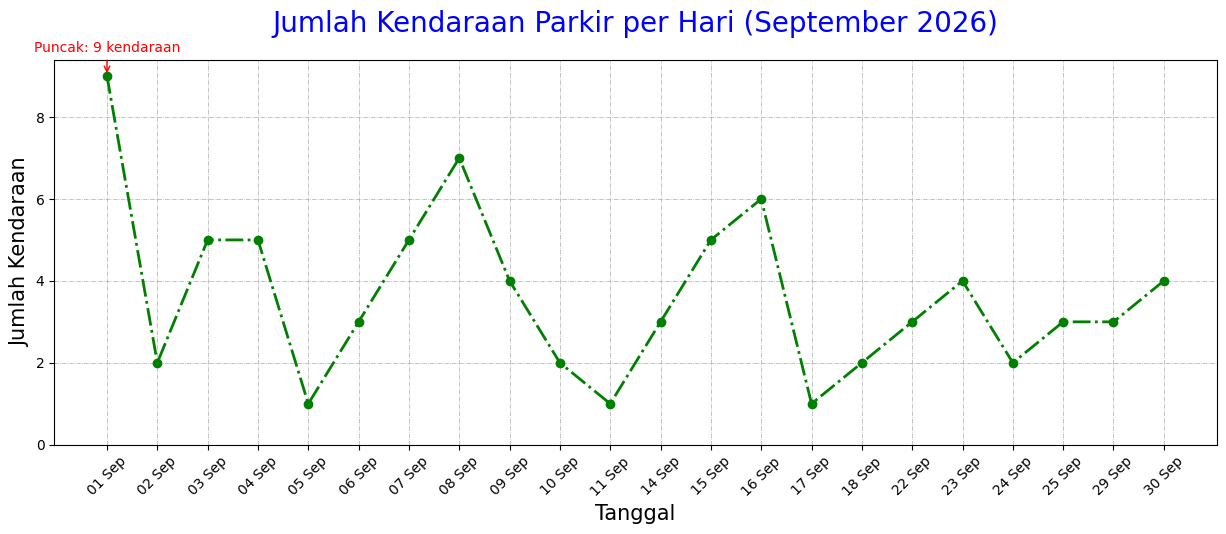

In [ ]:
plt.figure(figsize=(15, 5))
plt.plot(harian["Tanggal"].dt.strftime("%d %b"), harian["jumlah_kendaraan"],
         color="green", marker="o", linestyle="-.", linewidth=2)
plt.title("Jumlah Kendaraan Parkir per Hari (September 2026)", loc="center", pad=20, fontsize=20, color="blue")
plt.xlabel("Tanggal", fontsize=15)
plt.ylabel("Jumlah Kendaraan", fontsize=15)
plt.grid(color="darkgray", linestyle="-.", linewidth=0.5)
plt.ylim(ymin=0)
plt.xticks(rotation=45)

idx_puncak = harian["jumlah_kendaraan"].idxmax()
plt.annotate(f"Puncak: {harian.loc[idx_puncak, 'jumlah_kendaraan']} kendaraan",
             xy=(idx_puncak, harian.loc[idx_puncak, "jumlah_kendaraan"]),
             xytext=(idx_puncak, harian.loc[idx_puncak, "jumlah_kendaraan"] + 0.6),
             color="red", ha="center", arrowprops=dict(arrowstyle="->", color="red"))
plt.savefig("grafik/01_line_harian.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Visualisasi 2 — Bar Chart: Kendaraan per Area Parkir

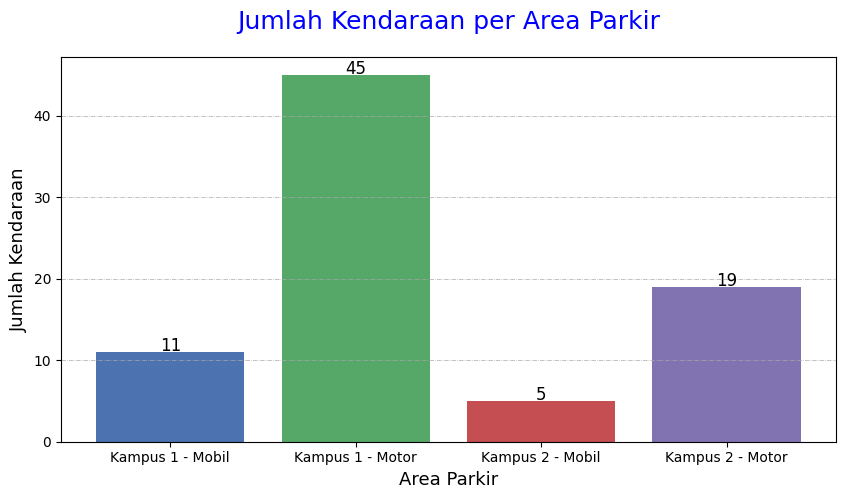

In [ ]:
plt.figure(figsize=(10, 5))
bars = plt.bar(per_area.index, per_area.values, color=["#4C72B0", "#55A868", "#C44E52", "#8172B2"][:len(per_area)])
plt.title("Jumlah Kendaraan per Area Parkir", pad=20, fontsize=18, color="blue")
plt.xlabel("Area Parkir", fontsize=13)
plt.ylabel("Jumlah Kendaraan", fontsize=13)
plt.grid(axis="y", color="darkgray", linestyle="-.", linewidth=0.5)
for b in bars:
    plt.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.1, int(b.get_height()), ha="center", fontsize=12)
plt.savefig("grafik/02_bar_area.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Visualisasi 3 — Pie Chart: Komposisi Status Pengguna

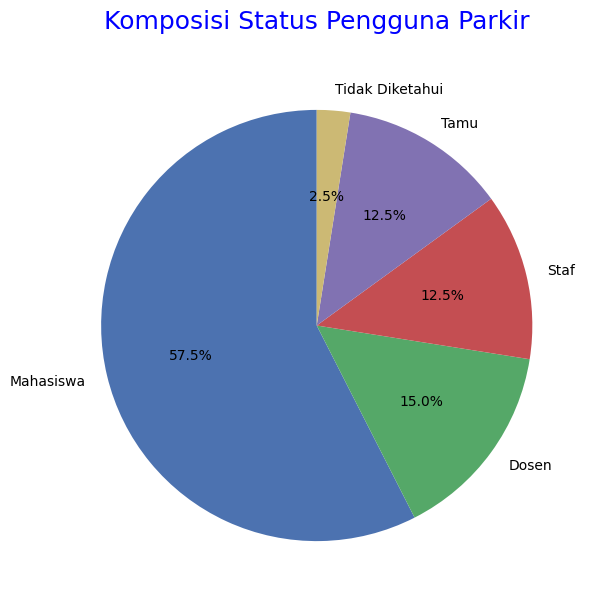

In [ ]:
plt.figure(figsize=(7, 7))
plt.pie(per_status.values, labels=per_status.index, autopct="%1.1f%%", startangle=90,
        colors=["#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974"][:len(per_status)])
plt.title("Komposisi Status Pengguna Parkir", fontsize=18, color="blue", pad=20)
plt.savefig("grafik/03_pie_status.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Visualisasi 4 — Histogram: Distribusi Durasi Parkir

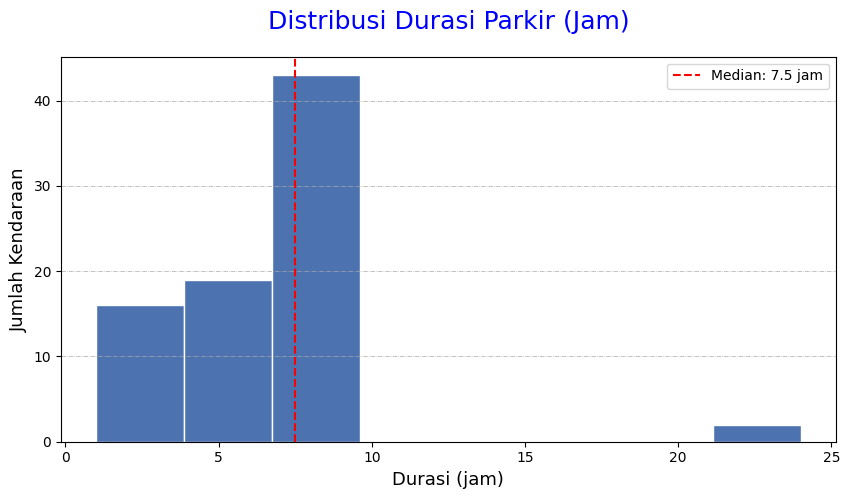

In [ ]:
plt.figure(figsize=(10, 5))
plt.hist(df_bersih["Durasi_Jam"], bins=8, color="#4C72B0", edgecolor="white")
plt.title("Distribusi Durasi Parkir (Jam)", pad=20, fontsize=18, color="blue")
plt.xlabel("Durasi (jam)", fontsize=13)
plt.ylabel("Jumlah Kendaraan", fontsize=13)
plt.grid(axis="y", color="darkgray", linestyle="-.", linewidth=0.5)
plt.axvline(df_bersih["Durasi_Jam"].median(), color="red", linestyle="--", label=f"Median: {df_bersih['Durasi_Jam'].median():.1f} jam")
plt.legend()
plt.savefig("grafik/04_hist_durasi.png", dpi=150, bbox_inches="tight")
plt.show()

## 10. Visualisasi 5 — Bar Horizontal: Merk Kendaraan

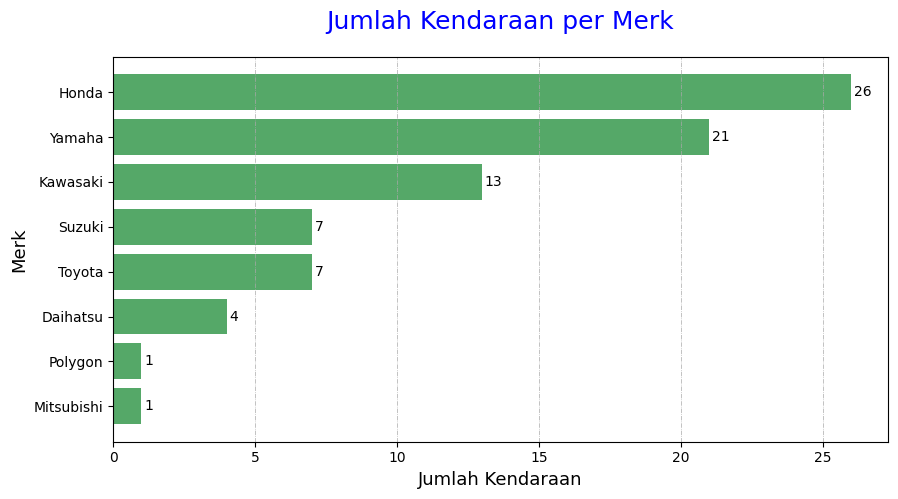

In [ ]:
plt.figure(figsize=(10, 5))
plt.barh(per_merk.index, per_merk.values, color="#55A868")
plt.title("Jumlah Kendaraan per Merk", pad=20, fontsize=18, color="blue")
plt.xlabel("Jumlah Kendaraan", fontsize=13)
plt.ylabel("Merk", fontsize=13)
plt.grid(axis="x", color="darkgray", linestyle="-.", linewidth=0.5)
for i, v in enumerate(per_merk.values):
    plt.text(v + 0.1, i, str(v), va="center")
plt.savefig("grafik/05_barh_merk.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. Visualisasi 6 — Rata-rata Durasi Parkir per Status

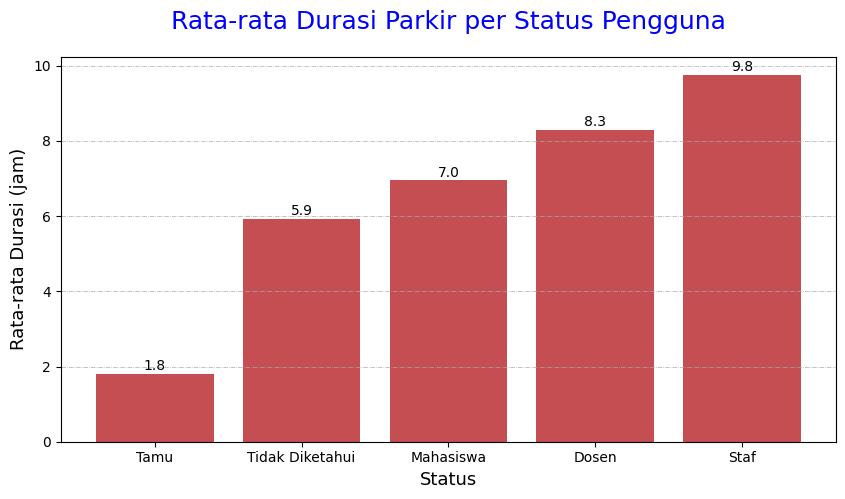

In [ ]:
plt.figure(figsize=(10, 5))
bars = plt.bar(durasi_status.index, durasi_status.values, color="#C44E52")
plt.title("Rata-rata Durasi Parkir per Status Pengguna", pad=20, fontsize=18, color="blue")
plt.xlabel("Status", fontsize=13)
plt.ylabel("Rata-rata Durasi (jam)", fontsize=13)
plt.grid(axis="y", color="darkgray", linestyle="-.", linewidth=0.5)
for b in bars:
    plt.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.1, f"{b.get_height():.1f}", ha="center")
plt.savefig("grafik/06_bar_durasi_status.png", dpi=150, bbox_inches="tight")
plt.show()

## 12. Dashboard Ringkasan (Subplot 2×2)


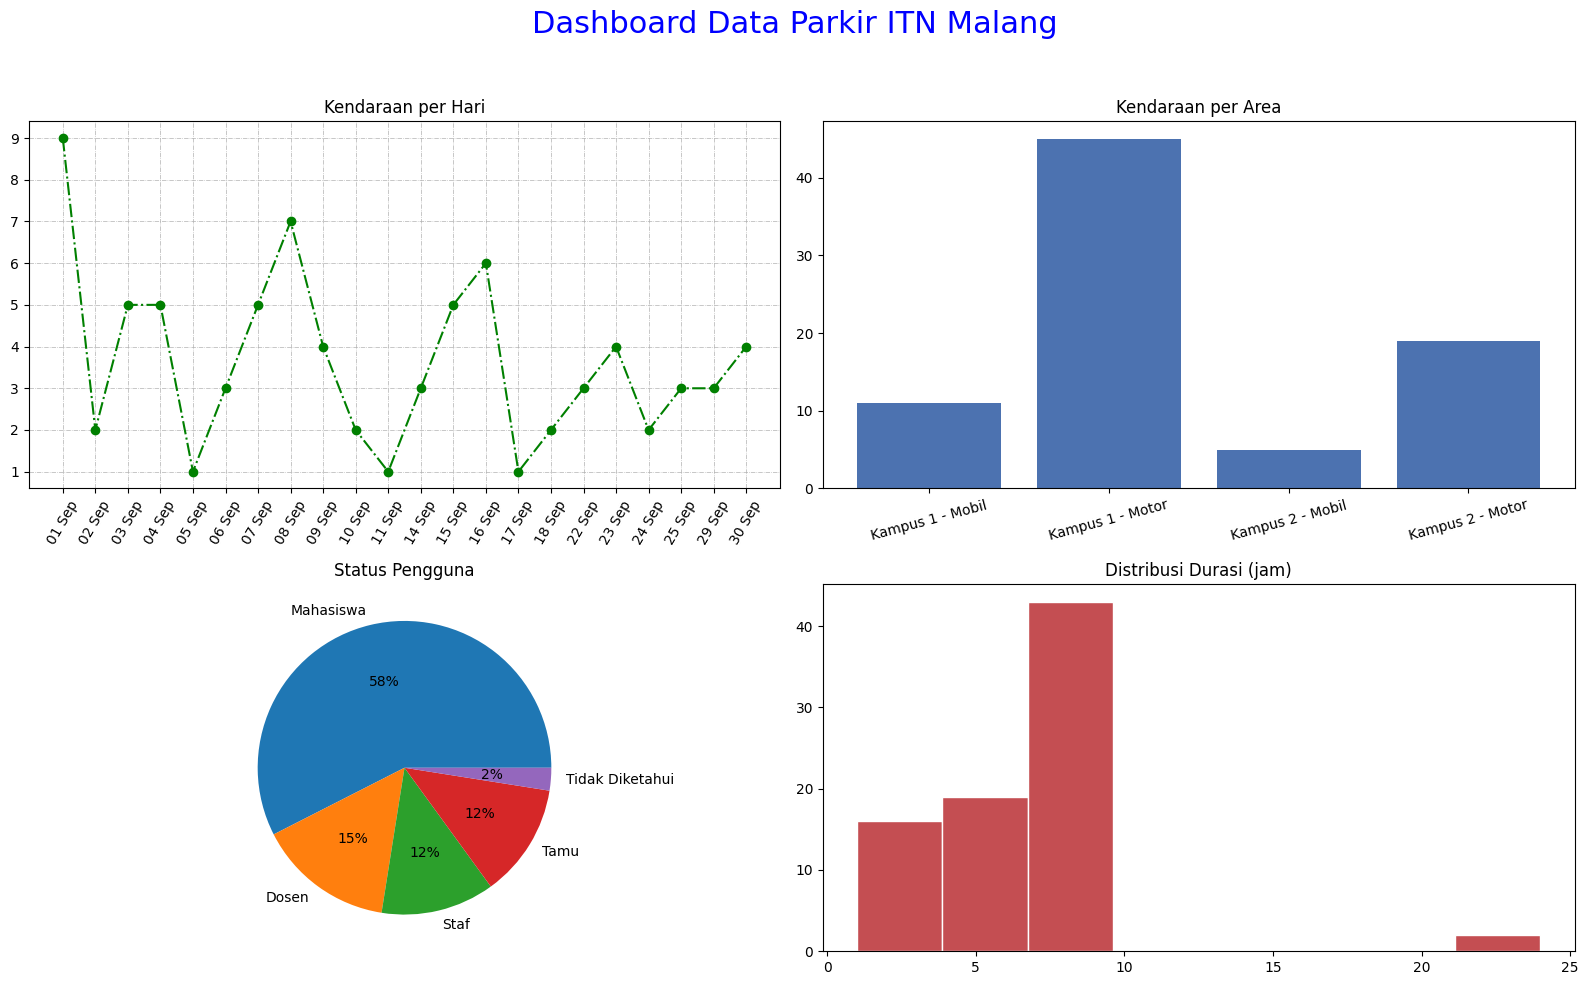

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle("Dashboard Data Parkir ITN Malang", fontsize=22, color="blue")

ax[0, 0].plot(harian["Tanggal"].dt.strftime("%d %b"), harian["jumlah_kendaraan"], color="green", marker="o", linestyle="-.")
ax[0, 0].set_title("Kendaraan per Hari"); ax[0, 0].tick_params(axis="x", rotation=60); ax[0, 0].grid(linestyle="-.", linewidth=0.5)

ax[0, 1].bar(per_area.index, per_area.values, color="#4C72B0")
ax[0, 1].set_title("Kendaraan per Area"); ax[0, 1].tick_params(axis="x", rotation=15)

ax[1, 0].pie(per_status.values, labels=per_status.index, autopct="%1.0f%%")
ax[1, 0].set_title("Status Pengguna")

ax[1, 1].hist(df_bersih["Durasi_Jam"], bins=8, color="#C44E52", edgecolor="white")
ax[1, 1].set_title("Distribusi Durasi (jam)")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("grafik/07_dashboard.png", dpi=150, bbox_inches="tight")
plt.show()

## 13. Kesimpulan



In [ ]:
hari_puncak = harian.loc[harian["jumlah_kendaraan"].idxmax()]
print(f"1. Total kendaraan valid: {len(df_bersih)}; puncak harian {hari_puncak['Tanggal'].strftime('%d %b %Y')} ({hari_puncak['jumlah_kendaraan']} kendaraan).")
print(f"2. Area paling ramai: {per_area.idxmax()} ({per_area.max()} kendaraan).")
print(f"3. Status pengguna terbanyak: {per_status.idxmax()} ({per_status.max() / per_status.sum():.0%}).")
print(f"4. Merk terbanyak: {per_merk.idxmax()} ({per_merk.max()} kendaraan).")
print(f"5. Rata-rata durasi parkir: {df_bersih['Durasi_Jam'].mean():.1f} jam; median {df_bersih['Durasi_Jam'].median():.1f} jam.")
print(f"6. Kategori durasi: {df_bersih['Kategori_Durasi'].value_counts().to_dict()}")

1. Total kendaraan valid: 80; puncak harian 01 Sep 2026 (9 kendaraan).
2. Area paling ramai: Kampus 1 - Motor (45 kendaraan).
3. Status pengguna terbanyak: Mahasiswa (57%).
4. Merk terbanyak: Honda (26 kendaraan).
5. Rata-rata durasi parkir: 6.8 jam; median 7.5 jam.
6. Kategori durasi: {'Sedang': 47, 'Lama': 26, 'Singkat': 7}
